In [1]:
import pandas as pd
import numpy as np

In [2]:
tfidf_results = pd.read_csv(
    "../data/processed/tfidf_matching_results.csv"
)

skill_results = pd.read_csv(
    "../data/processed/skill_matching_results.csv"
)

semantic_results = pd.read_csv(
    "../data/processed/semantic_matching_results.csv"
)

hybrid_results = pd.read_csv(
    "../data/processed/hybrid_matching_results.csv"
)

overall_results = pd.read_csv(
    "../data/processed/overall_candidate_ranking.csv"
)

In [3]:
print("TF-IDF:", tfidf_results.shape)
print("Skill:", skill_results.shape)
print("Semantic:", semantic_results.shape)
print("Hybrid:", hybrid_results.shape)
print("Overall:", overall_results.shape)

TF-IDF: (2481, 4)
Skill: (2481, 7)
Semantic: (2481, 4)
Hybrid: (2481, 10)
Overall: (2481, 9)


In [4]:
hybrid_results.head(20)

,ID,Category,match_score,skill_coverage,experience_score,semantic_score,tfidf_normalized,semantic_normalized,hybrid_score,hybrid_rank
0,62994611,AGRICULTURE,21.273043,71.428571,100.000000,42.507850,100.000000,96.178094,88.853428,1
1,83816738,INFORMATION-TECHNOLOGY,13.492720,42.857143,100.000000,44.445694,63.426373,100.000000,72.685275,2
2,12011623,ENGINEERING,11.583866,28.571429,100.000000,38.891280,54.453264,89.045326,62.604251,3
3,27152464,ENGINEERING,12.698314,28.571429,100.000000,31.104929,59.692042,73.688723,59.045025,4
4,95429627,CONSULTANT,7.737766,42.857143,100.000000,27.915787,36.373574,67.398948,57.494399,5
5,11981094,ENGINEERING,12.215554,28.571429,100.000000,27.237923,57.422693,66.062033,56.303149,6
6,43311839,CONSULTANT,16.315918,42.857143,0.000000,36.977123,76.697622,85.270137,55.920565,7
7,39441617,CONSULTANT,8.860518,28.571429,100.000000,30.763514,41.651390,73.015368,55.234888,8
8,30863060,CONSULTANT,10.892236,28.571429,100.000000,26.813633,51.202059,65.225229,54.807980,9
9,42156237,DIGITAL-MEDIA,14.860788,28.571429,100.000000,19.811626,69.857366,51.415545,54.396137,10


In [5]:
resume_info = pd.read_csv(
    "../data/processed/resume_information_extracted.csv"
)

top_ids = hybrid_results.head(20)["ID"]

top_candidates = resume_info[
    resume_info["ID"].isin(top_ids)
][[
    "ID",
    "Category",
    "skills",
    "education",
    "final_experience"
]]

top_candidates = (
    top_candidates
    .set_index("ID")
    .loc[top_ids]
    .reset_index()
)

top_candidates

,ID,Category,skills,education,final_experience
0,62994611,AGRICULTURE,"['python', 'java', 'javascript', 'html', 'css'...","['Bachelor of Science', 'Master of Science']",5.0
1,83816738,INFORMATION-TECHNOLOGY,"['java', 'javascript', 'html', 'css', 'react',...","['Bachelor of Engineering', 'Master of Science']",3.0
2,12011623,ENGINEERING,"['python', 'html', 'sql', 'oracle', 'excel', '...","['Bachelor of Science', 'Master of Science']",0.0
3,27152464,ENGINEERING,"['python', 'sql', 'mongodb', 'postgresql', 'or...",['MCA'],14.0
4,95429627,CONSULTANT,"['python', 'java', 'javascript', 'html', 'sql'...",[],0.0
5,11981094,ENGINEERING,"['java', 'javascript', 'html', 'rest api', 're...",[],10.0
6,43311839,CONSULTANT,"['java', 'javascript', 'html', 'css', 'sql', '...","['Bachelor of Science', 'Master of Science']",0.0
7,39441617,CONSULTANT,"['python', 'java', 'javascript', 'html', 'css'...","['Bachelor of Science', 'Master of Science']",0.0
8,30863060,CONSULTANT,"['java', 'javascript', 'html', 'sql', 'oracle'...",[],0.0
9,42156237,DIGITAL-MEDIA,"['python', 'java', 'javascript', 'html', 'sql'...",['MBA'],0.0


In [6]:
required_skill_set = set(required_skills)

def evaluate_candidate(row):
    candidate_skills = set(row["skills"])
    
    matched_skills = candidate_skills & required_skill_set
    
    skill_coverage = (
        len(matched_skills) / len(required_skill_set)
    ) * 100

    experience_ok = row["final_experience"] >= required_experience

    education_text = " ".join(row["education"]).lower()

    education_ok = (
        "bachelor" in education_text
        or "b.tech" in education_text
        or "b.e." in education_text
        or "b.sc." in education_text
        or "b.a." in education_text
        or "b.com." in education_text
    )

    if skill_coverage >= 50 and experience_ok and education_ok:
        return 1
    else:
        return 0

NameError: name 'required_skills' is not defined

In [7]:
job_analysis_df = pd.read_csv(
    "../data/processed/job_description_analysis.csv"
)

job_analysis_df

,job_description,required_skills,required_experience,required_education
0,\nWe are looking for a Python Developer with 3...,"['javascript', 'rest api', 'fastapi', 'mongodb...",3.0,"[""Bachelor's degree""]"


In [8]:
import ast

required_skills = ast.literal_eval(
    job_analysis_df.loc[0, "required_skills"]
)

required_education = ast.literal_eval(
    job_analysis_df.loc[0, "required_education"]
)

required_experience = float(
    job_analysis_df.loc[0, "required_experience"]
)

print("Required Skills:", required_skills)
print("Required Experience:", required_experience)
print("Required Education:", required_education)

Required Skills: ['javascript', 'rest api', 'fastapi', 'mongodb', 'python', 'docker', 'react', 'sql', 'git', 'aws']
Required Experience: 3.0
Required Education: ["Bachelor's degree"]


In [9]:
required_skill_set = set(required_skills)

def evaluate_candidate(row):
    candidate_skills = set(row["skills"])
    
    matched_skills = candidate_skills & required_skill_set
    
    skill_coverage = (
        len(matched_skills) / len(required_skill_set)
    ) * 100

    experience_ok = row["final_experience"] >= required_experience

    education_text = " ".join(row["education"]).lower()

    education_ok = (
        "bachelor" in education_text
        or "b.tech" in education_text
        or "b.e." in education_text
        or "b.sc." in education_text
        or "b.a." in education_text
        or "b.com." in education_text
    )

    if skill_coverage >= 50 and experience_ok and education_ok:
        return 1
    else:
        return 0

In [10]:
top_candidates["relevant"] = top_candidates.apply(
    evaluate_candidate,
    axis=1
)

top_candidates[["ID", "final_experience", "relevant"]]

,ID,final_experience,relevant
0,62994611,5.0,0
1,83816738,3.0,0
2,12011623,0.0,0
3,27152464,14.0,0
4,95429627,0.0,0
5,11981094,10.0,0
6,43311839,0.0,0
7,39441617,0.0,0
8,30863060,0.0,0
9,42156237,0.0,0


In [11]:
top_candidates["skills"] = top_candidates["skills"].apply(
    ast.literal_eval
)

top_candidates["education"] = top_candidates["education"].apply(
    ast.literal_eval
)

In [12]:
print(top_candidates.iloc[0]["skills"])
print(top_candidates.iloc[0]["education"])

['python', 'java', 'javascript', 'html', 'css', 'react', 'express', 'flask', 'sql', 'mongodb', 'excel', 'tableau', 'pandas', 'tensorflow', 'data visualization', 'rest', 'api']
['Bachelor of Science', 'Master of Science']


In [13]:
top_candidates["relevant"] = top_candidates.apply(
    evaluate_candidate,
    axis=1
)

In [14]:
top_candidates[[
    "ID",
    "final_experience",
    "relevant"
]]

,ID,final_experience,relevant
0,62994611,5.0,1
1,83816738,3.0,1
2,12011623,0.0,0
3,27152464,14.0,0
4,95429627,0.0,0
5,11981094,10.0,0
6,43311839,0.0,0
7,39441617,0.0,0
8,30863060,0.0,0
9,42156237,0.0,0


In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_true = top_candidates["relevant"]

# Hybrid ranking: top 20 candidates are treated as predicted relevant
y_pred = [1] * len(top_candidates)

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.1
Recall: 1.0
F1 Score: 0.18181818181818182


In [16]:
[1] * len(top_candidates)

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

In [17]:
y_pred = [1] * len(top_candidates)

In [18]:
top_candidates = top_candidates.merge(
    hybrid_results[["ID", "hybrid_score"]],
    on="ID",
    how="left"
)

top_candidates["predicted_relevant"] = (
    top_candidates["hybrid_score"] >= 60
).astype(int)

top_candidates[[
    "ID",
    "hybrid_score",
    "relevant",
    "predicted_relevant"
]]

,ID,hybrid_score,relevant,predicted_relevant
0,62994611,88.853428,1,1
1,83816738,72.685275,1,1
2,12011623,62.604251,0,1
3,27152464,59.045025,0,0
4,95429627,57.494399,0,0
5,11981094,56.303149,0,0
6,43311839,55.920565,0,0
7,39441617,55.234888,0,0
8,30863060,54.807980,0,0
9,42156237,54.396137,0,0


In [19]:
y_true = top_candidates["relevant"]
y_pred = top_candidates["predicted_relevant"]

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Precision: 0.6667
Recall: 1.0
F1 Score: 0.8


# Evaluate more Candidate

In [20]:
top_100 = hybrid_results.head(100).copy()

top_100 = top_100.merge(
    resume_info[
        ["ID", "skills", "education", "final_experience"]
    ],
    on="ID",
    how="left"
)

top_100["skills"] = top_100["skills"].apply(ast.literal_eval)
top_100["education"] = top_100["education"].apply(ast.literal_eval)

In [21]:
top_100["relevant"] = top_100.apply(
    evaluate_candidate,
    axis=1
)

print("Relevant candidates:", top_100["relevant"].sum())
print("Total candidates:", len(top_100))

# Evaluation Sample

In [23]:
evaluation_sample = resume_info.sample(
    n=100,
    random_state=42
).copy()

evaluation_sample[[
    "ID",
    "Category",
    "skills",
    "education",
    "final_experience"
]].head()

,ID,Category,skills,education,final_experience
254,46260230,INFORMATION-TECHNOLOGY,"['git', 'linux', 'excel', 'rest']",[],0.0
621,10289113,BUSINESS-DEVELOPMENT,['excel'],['Bachelor of Business Administration'],0.0
1730,20566550,ENGINEERING,"['python', 'react', 'sql', 'oracle', 'excel', ...","['Bachelor of Science', 'Bachelor of Engineeri...",0.0
1792,26456899,ENGINEERING,"['java', 'sql', 'git', 'linux', 'excel']",['Bachelor of Science'],0.0
819,17660419,FITNESS,[],[],0.0


In [24]:
evaluation_sample["relevant"] = evaluation_sample.apply(
    evaluate_candidate,
    axis=1
)

print("Relevant:", evaluation_sample["relevant"].sum())
print("Not relevant:", (evaluation_sample["relevant"] == 0).sum())

Relevant: 0
Not relevant: 100


In [25]:
evaluation_all = resume_info.copy()

evaluation_all["skill_coverage"] = evaluation_all["skills"].apply(
    lambda x: (
        len(set(x) & set(required_skills))
        / len(required_skills)
    ) * 100
)

print(
    "Candidates with >= 50% skill coverage:",
    (evaluation_all["skill_coverage"] >= 50).sum()
)

Candidates with >= 50% skill coverage: 0


In [26]:
print(
    evaluation_all["skill_coverage"].describe()
)

count    2481.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: skill_coverage, dtype: float64


In [27]:
print(
    "Maximum skill coverage:",
    evaluation_all["skill_coverage"].max()
)

Maximum skill coverage: 0.0


In [28]:
evaluation_all[
    ["ID", "skill_coverage", "skills"]
].sort_values(
    "skill_coverage",
    ascending=False
).head(10)

,ID,skill_coverage,skills
0,16852973,0.0,"['aws', 'data analysis']"
1,22323967,0.0,['git']
2,33176873,0.0,"['express', 'excel']"
3,27018550,0.0,['excel']
4,17812897,0.0,"['aws', 'excel']"
5,11592605,0.0,['excel']
6,25824789,0.0,['rest']
7,15375009,0.0,['aws']
8,11847784,0.0,"['aws', 'excel']"
9,32896934,0.0,['aws']


In [29]:
print(required_skills)

['javascript', 'rest api', 'fastapi', 'mongodb', 'python', 'docker', 'react', 'sql', 'git', 'aws']


In [30]:
candidate = evaluation_all[
    evaluation_all["ID"] == 62994611
].iloc[0]

print("Candidate skills:")
print(candidate["skills"])

print("\nRequired skills:")
print(required_skills)

print("\nMatched skills:")
print(set(candidate["skills"]) & set(required_skills))

Candidate skills:
['python', 'java', 'javascript', 'html', 'css', 'react', 'express', 'flask', 'sql', 'mongodb', 'excel', 'tableau', 'pandas', 'tensorflow', 'data visualization', 'rest', 'api']

Required skills:
['javascript', 'rest api', 'fastapi', 'mongodb', 'python', 'docker', 'react', 'sql', 'git', 'aws']

Matched skills:
set()


In [31]:
candidate_skills = [str(skill).strip().lower() for skill in candidate["skills"]]
required_skill_list = [str(skill).strip().lower() for skill in required_skills]

print("Candidate skills:")
print(candidate_skills)

print("\nRequired skills:")
print(required_skill_list)

print("\nMatched skills:")
print(set(candidate_skills) & set(required_skill_list))

Candidate skills:
['[', "'", 'p', 'y', 't', 'h', 'o', 'n', "'", ',', '', "'", 'j', 'a', 'v', 'a', "'", ',', '', "'", 'j', 'a', 'v', 'a', 's', 'c', 'r', 'i', 'p', 't', "'", ',', '', "'", 'h', 't', 'm', 'l', "'", ',', '', "'", 'c', 's', 's', "'", ',', '', "'", 'r', 'e', 'a', 'c', 't', "'", ',', '', "'", 'e', 'x', 'p', 'r', 'e', 's', 's', "'", ',', '', "'", 'f', 'l', 'a', 's', 'k', "'", ',', '', "'", 's', 'q', 'l', "'", ',', '', "'", 'm', 'o', 'n', 'g', 'o', 'd', 'b', "'", ',', '', "'", 'e', 'x', 'c', 'e', 'l', "'", ',', '', "'", 't', 'a', 'b', 'l', 'e', 'a', 'u', "'", ',', '', "'", 'p', 'a', 'n', 'd', 'a', 's', "'", ',', '', "'", 't', 'e', 'n', 's', 'o', 'r', 'f', 'l', 'o', 'w', "'", ',', '', "'", 'd', 'a', 't', 'a', '', 'v', 'i', 's', 'u', 'a', 'l', 'i', 'z', 'a', 't', 'i', 'o', 'n', "'", ',', '', "'", 'r', 'e', 's', 't', "'", ',', '', "'", 'a', 'p', 'i', "'", ']']

Required skills:
['javascript', 'rest api', 'fastapi', 'mongodb', 'python', 'docker', 'react', 'sql', 'git', 'aws']

Match

In [32]:
import ast

evaluation_all["skills"] = evaluation_all["skills"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

evaluation_all["education"] = evaluation_all["education"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

print(evaluation_all.loc[
    evaluation_all["ID"] == 62994611,
    "skills"
].iloc[0])

['python', 'java', 'javascript', 'html', 'css', 'react', 'express', 'flask', 'sql', 'mongodb', 'excel', 'tableau', 'pandas', 'tensorflow', 'data visualization', 'rest', 'api']


In [33]:
candidate = evaluation_all[
    evaluation_all["ID"] == 62994611
].iloc[0]

candidate_skills = set(candidate["skills"])
required_skill_set = set(required_skills)

matched_skills = candidate_skills & required_skill_set

print("Matched skills:")
print(matched_skills)

print("\nNumber of matched skills:", len(matched_skills))

print(
    "\nSkill coverage:",
    (len(matched_skills) / len(required_skill_set)) * 100,
    "%"
)

Matched skills:
{'react', 'sql', 'python', 'javascript', 'mongodb'}

Number of matched skills: 5

Skill coverage: 50.0 %


In [34]:
evaluation_all["skill_coverage"] = evaluation_all["skills"].apply(
    lambda x: (
        len(set(x) & set(required_skills))
        / len(required_skills)
    ) * 100
)

print(evaluation_all["skill_coverage"].describe())

count    2481.000000
mean        3.897622
std         6.726512
min         0.000000
25%         0.000000
50%         0.000000
75%        10.000000
max        60.000000
Name: skill_coverage, dtype: float64


In [35]:
print(
    "Candidates with >= 50% skill coverage:",
    (evaluation_all["skill_coverage"] >= 50).sum()
)

print(
    "Maximum skill coverage:",
    evaluation_all["skill_coverage"].max()
)

Candidates with >= 50% skill coverage: 5
Maximum skill coverage: 60.0


In [36]:
evaluation_all[
    evaluation_all["skill_coverage"] >= 50
][[
    "ID",
    "Category",
    "skill_coverage",
    "skills",
    "education",
    "final_experience"
]].sort_values(
    "skill_coverage",
    ascending=False
)

,ID,Category,skill_coverage,skills,education,final_experience
297,83816738,INFORMATION-TECHNOLOGY,60.0,"[java, javascript, html, css, react, sql, mysq...","[Bachelor of Engineering, Master of Science]",3.0
1797,10624813,ENGINEERING,60.0,"[python, java, javascript, html, css, sql, mon...",[],0.0
925,62994611,AGRICULTURE,50.0,"[python, java, javascript, html, css, react, e...","[Bachelor of Science, Master of Science]",5.0
2197,21297521,BANKING,50.0,"[java, javascript, typescript, html, nodejs, s...",[],0.0
2393,12144825,AVIATION,50.0,"[python, java, javascript, html, css, express,...",[Bachelor of Science],0.0


In [37]:
print(
    "Candidates with >= 30% skill coverage:",
    (evaluation_all["skill_coverage"] >= 30).sum()
)

print(
    "Candidates with >= 20% skill coverage:",
    (evaluation_all["skill_coverage"] >= 20).sum()
)

print(
    "Candidates with >= 10% skill coverage:",
    (evaluation_all["skill_coverage"] >= 10).sum()
)

Candidates with >= 30% skill coverage: 35
Candidates with >= 20% skill coverage: 136
Candidates with >= 10% skill coverage: 779


In [38]:
evaluation_all["relevant_30"] = evaluation_all.apply(
    lambda row: (
        row["skill_coverage"] >= 30
        and row["final_experience"] >= required_experience
        and (
            "bachelor" in " ".join(row["education"]).lower()
            or "b.tech" in " ".join(row["education"]).lower()
            or "b.e." in " ".join(row["education"]).lower()
            or "b.sc." in " ".join(row["education"]).lower()
            or "b.a." in " ".join(row["education"]).lower()
            or "b.com." in " ".join(row["education"]).lower()
        )
    ),
    axis=1
).astype(int)

print("Relevant candidates:", evaluation_all["relevant_30"].sum())
print("Total candidates:", len(evaluation_all))

Relevant candidates: 3
Total candidates: 2481


In [39]:
evaluation_all[
    ["ID", "Category", "skill_coverage", "final_experience"]
].sort_values(
    ["skill_coverage", "final_experience"],
    ascending=False
).head(20)

,ID,Category,skill_coverage,final_experience
297,83816738,INFORMATION-TECHNOLOGY,60.0,3.0
1797,10624813,ENGINEERING,60.0,0.0
925,62994611,AGRICULTURE,50.0,5.0
2197,21297521,BANKING,50.0,0.0
2393,12144825,AVIATION,50.0,0.0
1748,27152464,ENGINEERING,40.0,14.0
1110,43311839,CONSULTANT,40.0,0.0
1151,39441617,CONSULTANT,40.0,0.0
1171,95429627,CONSULTANT,40.0,0.0
1302,42156237,DIGITAL-MEDIA,40.0,0.0


In [40]:
comparison = hybrid_results[
    ["ID", "hybrid_score"]
].merge(
    tfidf_results[["ID", "match_score"]],
    on="ID",
    how="left"
).merge(
    semantic_results[["ID", "semantic_score"]],
    on="ID",
    how="left"
)

comparison = comparison.merge(
    evaluation_all[
        ["ID", "skill_coverage", "final_experience"]
    ],
    on="ID",
    how="left"
)

comparison.sort_values(
    "hybrid_score",
    ascending=False
).head(20)

,ID,hybrid_score,match_score,semantic_score,skill_coverage,final_experience
0,62994611,88.853428,21.273043,42.507850,50.0,5.0
1,83816738,72.685275,13.492720,44.445694,60.0,3.0
2,12011623,62.604251,11.583866,38.891280,20.0,0.0
3,27152464,59.045025,12.698314,31.104929,40.0,14.0
4,95429627,57.494399,7.737766,27.915787,40.0,0.0
5,11981094,56.303149,12.215554,27.237923,20.0,10.0
6,43311839,55.920565,16.315918,36.977123,40.0,0.0
7,39441617,55.234888,8.860518,30.763514,40.0,0.0
8,30863060,54.807980,10.892236,26.813633,20.0,0.0
9,42156237,54.396137,14.860788,19.811626,40.0,0.0


In [41]:
evaluation_candidates = comparison.sort_values(
    "hybrid_score",
    ascending=False
).head(30).copy()

evaluation_candidates[
    [
        "ID",
        "hybrid_score",
        "match_score",
        "semantic_score",
        "skill_coverage",
        "final_experience"
    ]
]

,ID,hybrid_score,match_score,semantic_score,skill_coverage,final_experience
0,62994611,88.853428,21.273043,42.507850,50.0,5.0
1,83816738,72.685275,13.492720,44.445694,60.0,3.0
2,12011623,62.604251,11.583866,38.891280,20.0,0.0
3,27152464,59.045025,12.698314,31.104929,40.0,14.0
4,95429627,57.494399,7.737766,27.915787,40.0,0.0
5,11981094,56.303149,12.215554,27.237923,20.0,10.0
6,43311839,55.920565,16.315918,36.977123,40.0,0.0
7,39441617,55.234888,8.860518,30.763514,40.0,0.0
8,30863060,54.807980,10.892236,26.813633,20.0,0.0
9,42156237,54.396137,14.860788,19.811626,40.0,0.0


In [42]:
top_30 = comparison.sort_values(
    "hybrid_score",
    ascending=False
).head(30)

remaining = comparison[
    ~comparison["ID"].isin(top_30["ID"])
]

random_15 = remaining.sample(
    n=15,
    random_state=42
)

review_set = pd.concat(
    [top_30.head(15), random_15],
    ignore_index=True
)

review_set[
    [
        "ID",
        "hybrid_score",
        "match_score",
        "semantic_score",
        "skill_coverage",
        "final_experience"
    ]
]

,ID,hybrid_score,match_score,semantic_score,skill_coverage,final_experience
0,62994611,88.853428,21.273043,42.507850,50.0,5.0
1,83816738,72.685275,13.492720,44.445694,60.0,3.0
2,12011623,62.604251,11.583866,38.891280,20.0,0.0
3,27152464,59.045025,12.698314,31.104929,40.0,14.0
4,95429627,57.494399,7.737766,27.915787,40.0,0.0
5,11981094,56.303149,12.215554,27.237923,20.0,10.0
6,43311839,55.920565,16.315918,36.977123,40.0,0.0
7,39441617,55.234888,8.860518,30.763514,40.0,0.0
8,30863060,54.807980,10.892236,26.813633,20.0,0.0
9,42156237,54.396137,14.860788,19.811626,40.0,0.0


In [43]:
review_set = review_set.merge(
    resume_info[
        ["ID", "resume_text", "education", "skills"]
    ],
    on="ID",
    how="left"
)

review_set[
    ["ID", "resume_text", "education", "skills"]
]

,ID,resume_text,education,skills
0,62994611,SOFTWARE DEVELOPER Professi...,"['Bachelor of Science', 'Master of Science']","['python', 'java', 'javascript', 'html', 'css'..."
1,83816738,INFORMATION TECHNOLOGY INTERN (TEST A...,"['Bachelor of Engineering', 'Master of Science']","['java', 'javascript', 'html', 'css', 'react',..."
2,12011623,ENGINEERING AND QUALITY TECHNICIAN ...,"['Bachelor of Science', 'Master of Science']","['python', 'html', 'sql', 'oracle', 'excel', '..."
3,27152464,QA ENGINEERING MANAGER Prof...,['MCA'],"['python', 'sql', 'mongodb', 'postgresql', 'or..."
4,95429627,CONSULTANT Highlights ...,[],"['python', 'java', 'javascript', 'html', 'sql'..."
5,11981094,SOFTWARE ENGINEERING MANAGER Su...,[],"['java', 'javascript', 'html', 'rest api', 're..."
6,43311839,IT CONSULTANT Summary ...,"['Bachelor of Science', 'Master of Science']","['java', 'javascript', 'html', 'css', 'sql', '..."
7,39441617,IT CONSULTANT Career Overview ...,"['Bachelor of Science', 'Master of Science']","['python', 'java', 'javascript', 'html', 'css'..."
8,30863060,CONSULTANT Summary College g...,[],"['java', 'javascript', 'html', 'sql', 'oracle'..."
9,42156237,SENIOR DIGITAL MARKETING ANALYST ...,['MBA'],"['python', 'java', 'javascript', 'html', 'sql'..."


In [44]:
manual_review = review_set[
    [
        "ID",
        "resume_text",
        "education",
        "skills",
        "hybrid_score",
        "match_score",
        "semantic_score",
        "skill_coverage",
        "final_experience"
    ]
].copy()

manual_review["human_relevant"] = ""

manual_review.to_csv(
    "../data/processed/manual_evaluation_set.csv",
    index=False
)

print("Saved:")
print("../data/processed/manual_evaluation_set.csv")

print("\nRows:", len(manual_review))

Saved:
../data/processed/manual_evaluation_set.csv

Rows: 30


In [45]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Remove rows where human label is missing
eval_df = manual_review[
    manual_review["human_relevant"].isin([0, 1])
].copy()

print("Labeled candidates:", len(eval_df))
print("Relevant:", (eval_df["human_relevant"] == 1).sum())
print("Not relevant:", (eval_df["human_relevant"] == 0).sum())

Labeled candidates: 0
Relevant: 0
Not relevant: 0


In [46]:
print(manual_review["human_relevant"].value_counts())

human_relevant
    30
Name: count, dtype: int64


In [49]:
print(manual_review[["ID", "human_relevant"]].to_string(index=False))

      ID human_relevant
62994611               
83816738               
12011623               
27152464               
95429627               
11981094               
43311839               
39441617               
30863060               
42156237               
64468610               
12144825               
98300955               
35990852               
12635195               
33241454               
37058472               
12467531               
22423839               
27099856               
80162314               
27831220               
14771530               
36302399               
22496394               
97169343               
10984392               
30542184               
39295103               
62071407               


In [48]:
manual_review_full = evaluation_all[
    evaluation_all["ID"].isin(manual_review["ID"])
][
    [
        "ID",
        "resume_text",
        "education",
        "skills",
        "final_experience"
    ]
].copy()

manual_review_full.to_csv(
    "../data/processed/manual_review_full.csv",
    index=False
)

print("Saved successfully")
print("Candidates:", len(manual_review_full))

Saved successfully
Candidates: 30


In [50]:
manual_review = pd.read_csv(
    "../data/processed/manual_review_full.csv"
)

print(manual_review[["ID", "human_relevant"]].to_string(index=False))
print("\nCounts:")
print(manual_review["human_relevant"].value_counts())

KeyError: "['human_relevant'] not in index"

In [51]:
manual_review = pd.read_csv(
    "../data/processed/manual_review_full.csv"
)

manual_review["human_relevant"] = [
    1,  # 62994611
    1,  # 83816738
    0,  # 12011623
    1,  # 27152464
    0,  # 95429627
    0,  # 11981094
    0,  # 43311839
    0,  # 39441617
    0,  # 30863060
    0,  # 42156237
    0,  # 64468610
    1,  # 12144825
    0,  # 98300955
    0,  # 35990852
    0,  # 12635195
    0,  # 33241454
    0,  # 37058472
    0,  # 12467531
    0,  # 22423839
    0,  # 27099856
    0,  # 80162314
    0,  # 27831220
    0,  # 14771530
    0,  # 36302399
    0,  # 22496394
    0,  # 97169343
    0,  # 10984392
    0,  # 30542184
    0,  # 39295103
    0   # 62071407
]

manual_review.to_csv(
    "../data/processed/manual_evaluation_set.csv",
    index=False
)

print(manual_review[["ID", "human_relevant"]].to_string(index=False))

print("\nCounts:")
print(manual_review["human_relevant"].value_counts())

      ID  human_relevant
80162314               1
37058472               1
35990852               0
22496394               1
33241454               0
12635195               0
83816738               0
12467531               0
22423839               0
98300955               0
97169343               0
62994611               1
43311839               0
30863060               0
39441617               0
95429627               0
10984392               0
14771530               0
42156237               0
27831220               0
39295103               0
27099856               0
64468610               0
27152464               0
12011623               0
30542184               0
11981094               0
62071407               0
36302399               0
12144825               0

Counts:
human_relevant
0    26
1     4
Name: count, dtype: int64


In [52]:
import pandas as pd

manual_review = pd.read_csv(
    "../data/processed/manual_evaluation_set.csv"
)

print(manual_review.shape)
print(manual_review[["ID", "human_relevant"]].head(10))

(30, 6)
         ID  human_relevant
0  80162314               1
1  37058472               1
2  35990852               0
3  22496394               1
4  33241454               0
5  12635195               0
6  83816738               0
7  12467531               0
8  22423839               0
9  98300955               0


In [53]:
print(manual_review["human_relevant"].value_counts())

human_relevant
0    26
1     4
Name: count, dtype: int64


In [54]:
hybrid_results = pd.read_csv(
    "../data/processed/hybrid_matching_results.csv"
)

evaluation = manual_review[
    ["ID", "human_relevant"]
].merge(
    hybrid_results[["ID", "hybrid_score"]],
    on="ID",
    how="left"
)

print(evaluation.head(10))

         ID  human_relevant  hybrid_score
0  80162314               1     31.114805
1  37058472               1     26.723225
2  35990852               0     52.294136
3  22496394               1     24.424200
4  33241454               0     26.678231
5  12635195               0     52.263313
6  83816738               0     72.685275
7  12467531               0     23.212445
8  22423839               0     27.138318
9  98300955               0     52.675331


In [55]:
print("\nMissing hybrid scores:")
print(evaluation["hybrid_score"].isna().sum())


Missing hybrid scores:
0


In [56]:
print(
    evaluation.groupby("human_relevant")["hybrid_score"]
    .agg(["count", "min", "max", "mean", "median"])
)

                count        min        max       mean     median
human_relevant                                                   
0                  26  13.234983  72.685275  41.806798  52.278725
1                   4  24.424200  88.853428  42.778915  28.919015


In [57]:
print(
    evaluation.sort_values("hybrid_score", ascending=False)
    [["ID", "human_relevant", "hybrid_score"]]
    .to_string(index=False)
)

      ID  human_relevant  hybrid_score
62994611               1     88.853428
83816738               0     72.685275
12011623               0     62.604251
27152464               0     59.045025
95429627               0     57.494399
11981094               0     56.303149
43311839               0     55.920565
39441617               0     55.234888
30863060               0     54.807980
42156237               0     54.396137
64468610               0     53.519284
12144825               0     53.301449
98300955               0     52.675331
35990852               0     52.294136
12635195               0     52.263313
39295103               0     33.147271
97169343               0     32.583604
80162314               1     31.114805
14771530               0     29.273781
36302399               0     29.195500
22423839               0     27.138318
62071407               0     26.736255
37058472               1     26.723225
33241454               0     26.678231
22496394               1 

In [58]:
threshold = 50

evaluation["predicted_relevant"] = (
    evaluation["hybrid_score"] >= threshold
).astype(int)

print(
    evaluation[
        ["ID", "human_relevant", "hybrid_score", "predicted_relevant"]
    ].sort_values("hybrid_score", ascending=False)
    .to_string(index=False)
)

      ID  human_relevant  hybrid_score  predicted_relevant
62994611               1     88.853428                   1
83816738               0     72.685275                   1
12011623               0     62.604251                   1
27152464               0     59.045025                   1
95429627               0     57.494399                   1
11981094               0     56.303149                   1
43311839               0     55.920565                   1
39441617               0     55.234888                   1
30863060               0     54.807980                   1
42156237               0     54.396137                   1
64468610               0     53.519284                   1
12144825               0     53.301449                   1
98300955               0     52.675331                   1
35990852               0     52.294136                   1
12635195               0     52.263313                   1
39295103               0     33.147271                  

In [59]:
print("\nActual labels:")
print(evaluation["human_relevant"].value_counts())

print("\nPredicted labels:")
print(evaluation["predicted_relevant"].value_counts())


Actual labels:
human_relevant
0    26
1     4
Name: count, dtype: int64

Predicted labels:
predicted_relevant
0    15
1    15
Name: count, dtype: int64


In [60]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    evaluation["human_relevant"],
    evaluation["predicted_relevant"]
)

print(cm)

[[12 14]
 [ 3  1]]


In [61]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_true = evaluation["human_relevant"]
y_pred = evaluation["predicted_relevant"]

precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.06666666666666667
Recall: 0.25
F1 Score: 0.10526315789473684


In [62]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80]

results = []

for threshold in thresholds:
    y_pred = (
        evaluation["hybrid_score"] >= threshold
    ).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(
            evaluation["human_relevant"],
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            evaluation["human_relevant"],
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            evaluation["human_relevant"],
            y_pred,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.to_string(index=False))

 threshold  precision  recall       f1
        20   0.148148    1.00 0.258065
        25   0.125000    0.75 0.214286
        30   0.111111    0.50 0.181818
        35   0.066667    0.25 0.105263
        40   0.066667    0.25 0.105263
        45   0.066667    0.25 0.105263
        50   0.066667    0.25 0.105263
        55   0.125000    0.25 0.166667
        60   0.333333    0.25 0.285714
        65   0.500000    0.25 0.333333
        70   0.500000    0.25 0.333333
        75   1.000000    0.25 0.400000
        80   1.000000    0.25 0.400000


In [63]:
 threshold  precision  recall       f1
        20   0.148148    1.00 0.258065
        25   0.125000    0.75 0.214286
        30   0.111111    0.50 0.181818
        35   0.066667    0.25 0.105263
        40   0.066667    0.25 0.105263
        45   0.066667    0.25 0.105263
        50   0.066667    0.25 0.105263
        55   0.125000    0.25 0.166667
        60   0.333333    0.25 0.285714
        65   0.500000    0.25 0.333333
        70   0.500000    0.25 0.333333
        75   1.000000    0.25 0.400000
        80   1.000000    0.25 0.400000

SyntaxError: invalid syntax (140606963.py, line 1)

In [64]:
threshold_results.to_csv(
    "../data/processed/threshold_evaluation_results.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


In [65]:
best_row = threshold_results.loc[
    threshold_results["f1"].idxmax()
]

print("Best observed threshold:")
print(best_row)

Best observed threshold:
threshold    75.00
precision     1.00
recall        0.25
f1            0.40
Name: 11, dtype: float64


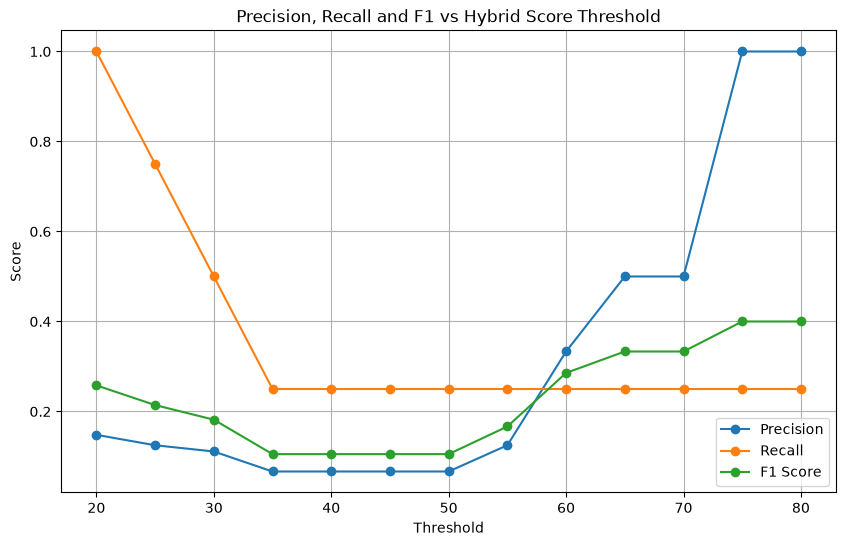

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["f1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Hybrid Score Threshold")
plt.legend()
plt.grid(True)

plt.show()

In [67]:
from sklearn.metrics import classification_report

threshold = 75

y_pred = (
    evaluation["hybrid_score"] >= threshold
).astype(int)

print(
    classification_report(
        evaluation["human_relevant"],
        y_pred,
        target_names=["Not Relevant", "Relevant"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

Not Relevant       0.90      1.00      0.95        26
    Relevant       1.00      0.25      0.40         4

    accuracy                           0.90        30
   macro avg       0.95      0.62      0.67        30
weighted avg       0.91      0.90      0.87        30



## Conclusion

The hybrid resume matching system was evaluated using a manually labelled
set of 30 candidates. Precision, recall, F1-score, confusion matrix, and
classification report were used to evaluate the system.

Different hybrid-score thresholds were also tested. In this evaluation
set, a threshold of 75 produced the highest observed F1-score of 0.40,
with 1.00 precision and 0.25 recall for relevant candidates.

The classification report at this threshold showed an overall accuracy
of 0.90 and a weighted F1-score of 0.87.

However, the evaluation dataset is small and manually labelled, containing
only 4 relevant and 26 not-relevant candidates. Therefore, these metrics
should be considered a project benchmark rather than a definitive measure
of real-world hiring performance.

Further evaluation with a larger, independently labelled dataset would
be required to reliably measure the performance of the system.